In [ ]:
import cv2
import matplotlib.pyplot as plt


### using global threshold for creating a binary picture foreground and background


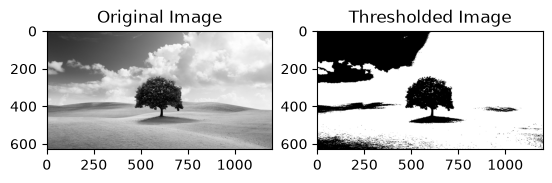

In [ ]:
img = cv2.imread('image.jpg', 0)

ret, thresh = cv2.threshold(
    img, 127, 255, cv2.THRESH_BINARY
)

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap='gray')
plt.title("Thresholded Image")

plt.show()

### Using Ostu to find the threshold value 

In [4]:
gray = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(gray, (5, 5), 0)          # smoothing helps Otsu


In [5]:
_, fixed = cv2.threshold(blur, 127, 255, cv2.THRESH_BINARY)
t_otsu, otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 31, 5)
print('Otsu threshold chosen automatically:', t_otsu)



Otsu threshold chosen automatically: 149.0


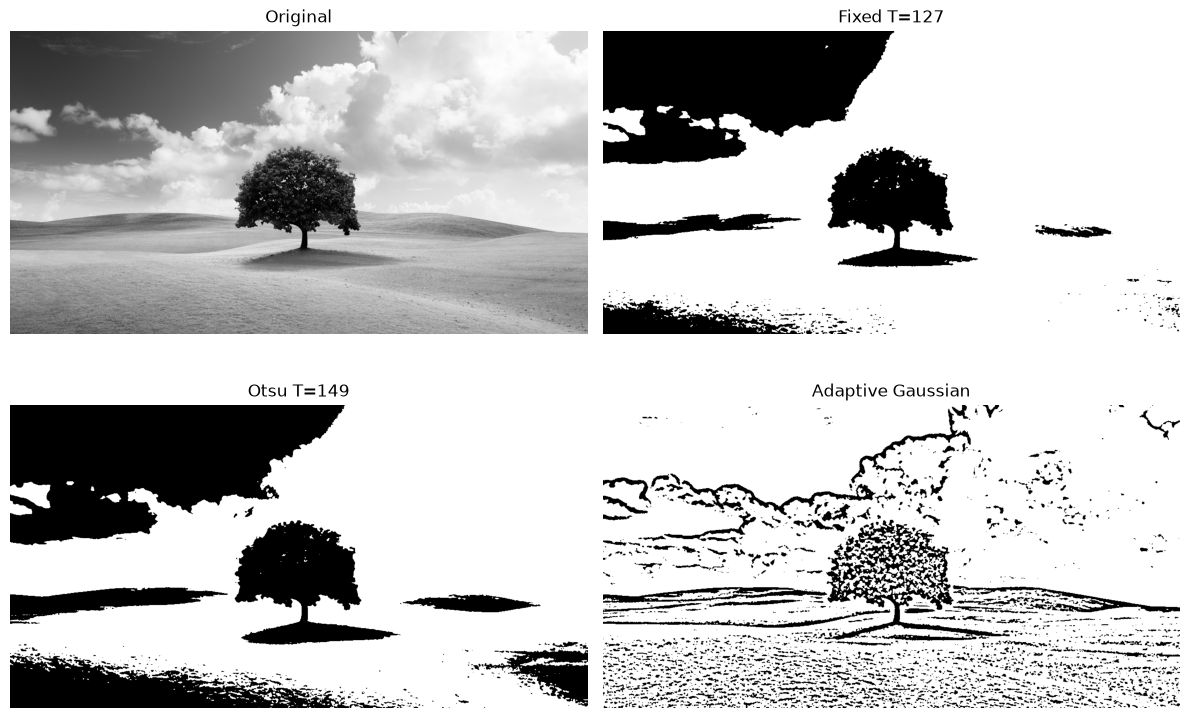

In [12]:
imgs = [gray, fixed, otsu, adaptive]

titles =['Original', 'Fixed T=127',f'Otsu T={t_otsu:.0f}', 'Adaptive Gaussian']


fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for a, im, t in zip(ax.flatten(), imgs , titles):
    a.imshow(im, cmap='gray')
    a.set_title(t)
    a.axis('off')

plt.tight_layout()
plt.show()

# Histogram with Otsu threshold marked


C:\Users\Shekhar Kumar\AppData\Local\Temp\ipykernel_14940\2011158739.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(gray.ravel(), 256, [0, 256]); plt.axvline(t_otsu, color='r')


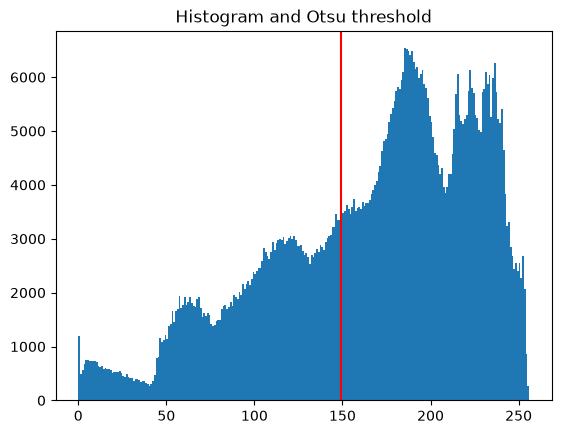

In [13]:
plt.hist(gray.ravel(), 256, [0, 256]); plt.axvline(t_otsu, color='r')
plt.title('Histogram and Otsu threshold'); plt.show()